# 📓 Multimodal AI Module 3: Visual Instruction Tuning with Frozen LLMs on MS-COCO
Welcome to Module 3 of Multimodal AI! In this tutorial, we will implement and train a **LLaVA-style Vision-Language Model (VLM)** using a real subset of the **MS-COCO Captions** dataset [cite: 16].

---

## 💡 1. The LLaVA Architecture: Frozen Foundation Backbones
Training end-to-end multimodal models from scratch is computationally expensive [cite: 16]. Modern Large Multimodal Models (LMMs) like **LLaVA**, **Flamingo**, **Frozen**, and **BLIP-2/3** solve this by connecting pre-trained, frozen unimodal backbones [cite: 16]:

1. **Frozen Vision Encoder:** A Vision Transformer (e.g., **CLIP-ViT**) extracts patch-level feature vectors $Z_v \in \mathbb{R}^{P \times d_v}$ [cite: 16].
2. **Trainable Multimodal Projector:** A lightweight 2-layer MLP projection network maps visual patch embeddings into the language model's word embedding dimension: $H_v = \text{MLP}(Z_v) \in \mathbb{R}^{P \times d_{\text{LLM}}}$ [cite: 16].
3. **Frozen Language Model (LLM):** A decoder-only language model (e.g., GPT-2 or LLaMA) treats the projected visual tokens as a soft prefix prepended to text token embeddings: $H = [H_v; H_t]$ [cite: 16].

```
Input Image ──► [Frozen CLIP-ViT] ──► Features Z_v ──► [Trainable Projector W] ──► Visual Tokens H_v ┐
                                                                                                      ├──► [Frozen LLM] ──► Text Output
Prompt Text ────────────────────────► Tokenizer  ──► Word Embeddings H_t ────────────────────────────┘
```

### Stage 1: Feature Alignment on Image-Caption Data
In **Stage 1 (Feature Alignment)**, the vision encoder and LLM are kept completely **frozen** ($100\%$ parameter retention) [cite: 16]. Only the **projection MLP** is updated on image-caption pairs (such as MS-COCO) so the LLM learns to perceive visual tokens as natural semantic prompts [cite: 16].

In [1]:
# Install required dependencies if in Colab/Jupyter
try:
    import transformers
    import datasets
except ImportError:
    !pip install -q transformers datasets torch torchvision accelerate pillow matplotlib ipywidgets

import os
import io
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, CLIPVisionModel, CLIPImageProcessor
from IPython.display import display, clear_output
import ipywidgets as widgets
from ipywidgets import interact, Dropdown, Text, IntSlider

# Device setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing on device: {device}")

torch.manual_seed(42)

Executing on device: cuda


## 📦 2. Loading Real Image-Caption Data (MS-COCO)
We load a compact slice of **real MS-COCO captions** using the Hugging Face `datasets` library.
Each instance provides a natural photograph spanning everyday scenes (people, vehicles, animals, indoors) paired with descriptive human reference captions [cite: 16].

Streaming 200 real COCO image-caption pairs on the fly...


Resolving data files:   0%|          | 0/96 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/96 [00:00<?, ?it/s]

Done! Collected 200 real pairs from MS-COCO 2017 (DavidPhilips/coco2017 - Streamed).


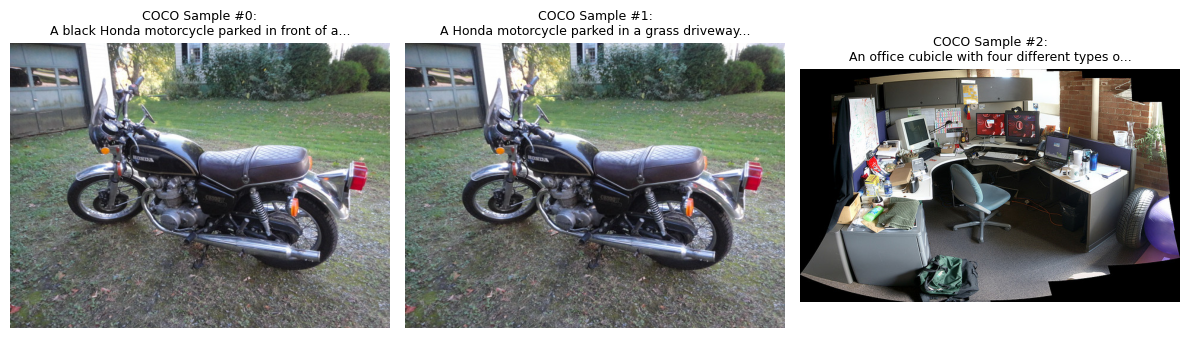

In [3]:
from datasets import load_dataset
from PIL import Image
import matplotlib.pyplot as plt

NUM_SAMPLES = 200

print(f"Streaming {NUM_SAMPLES} real COCO image-caption pairs on the fly...")

def extract_caption(example):
    """Safely extracts the caption string from various dataset field names."""
    for key in ["caption_en", "caption", "sentences", "text"]:
        if key in example and example[key]:
            val = example[key]
            if isinstance(val, list):
                first = val[0]
                return first.get("raw", str(first)) if isinstance(first, dict) else str(first)
            return str(val)
    return "A photo of an everyday scene."

coco_samples = []

try:
    # streaming=True prevents downloading the full 25k validation shard
    streamed_ds = load_dataset(
        "DavidPhilips/coco2017",
        split="validation",
        streaming=True
    )

    # .take(NUM_SAMPLES) streams only the first N samples directly over HTTP
    for item in streamed_ds.take(NUM_SAMPLES):
        img = item["image"].convert("RGB")
        cap = extract_caption(item)
        if len(cap.strip()) > 3:
            coco_samples.append({"image": img, "caption": cap})

    dataset_name = "MS-COCO 2017 (DavidPhilips/coco2017 - Streamed)"
except Exception as e:
    print(f"Notice on COCO stream: {e}\nFalling back to Flickr8k stream...")
    streamed_backup = load_dataset("jxie/flickr8k", split="train", streaming=True)
    for item in streamed_backup.take(NUM_SAMPLES):
        img = item["image"].convert("RGB")
        cap = extract_caption(item)
        if len(cap.strip()) > 3:
            coco_samples.append({"image": img, "caption": cap})
    dataset_name = "Flickr8k (Streamed)"

print(f"Done! Collected {len(coco_samples)} real pairs from {dataset_name}.")

# Preview 3 samples
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for idx in range(3):
    img = coco_samples[idx]["image"]
    cap = coco_samples[idx]["caption"]
    axes[idx].imshow(img)
    axes[idx].set_title(f"COCO Sample #{idx}:\n{cap[:45]}...", fontsize=9)
    axes[idx].axis("off")
plt.tight_layout()
plt.show()

In [2]:
from datasets import load_dataset
from PIL import Image

NUM_SAMPLES = 200

print(f"Loading {NUM_SAMPLES} real image-caption pairs in Parquet format...")

# Load from native Parquet repos without legacy .py scripts
try:
    # Official MS-COCO 2017 (stored as pure Parquet, no COCO.py script)
    # Using the validation split downloads only the first lightweight shard (~25k total rows)
    raw_dataset = load_dataset(
        "DavidPhilips/coco2017",
        split=f"validation[:{NUM_SAMPLES}]"
    )
    img_key = "image"
    caption_key = "caption"
    dataset_name = "MS-COCO 2017 (DavidPhilips/coco2017)"
except Exception as e:
    print(f"Notice: {e}\nFalling back to Flickr8k Parquet dataset...")
    raw_dataset = load_dataset(
        "jxie/flickr8k",
        split=f"train[:{NUM_SAMPLES}]"
    )
    img_key = "image"
    caption_key = "caption"
    dataset_name = "Flickr8k (jxie/flickr8k)"

def extract_caption(example):
    cap = example.get(caption_key, "")
    if isinstance(cap, list):
        return str(cap[0])
    return str(cap)

print(f"Successfully loaded {len(raw_dataset)} samples from {dataset_name}!")

# Visualize a 3-sample grid of real images and captions
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for idx in range(3):
    sample = raw_dataset[idx]
    img = sample[img_key].convert("RGB")
    cap = extract_caption(sample)
    axes[idx].imshow(img)
    axes[idx].set_title(f"Sample #{idx}:\n{cap[:50]}...", fontsize=9)
    axes[idx].axis("off")
plt.tight_layout()
plt.show()

Loading 200 real image-caption pairs in Parquet format...


README.md:   0%|          | 0.00/3.30k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/96 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/96 [00:00<?, ?it/s]

data/train-00000-of-00096.parquet: reconstructing file:   0%|          |  0.00B /  682MB            

...

data/train-00004-of-00096.parquet: reconstructing file:   0%|          |  0.00B /  652MB            

data/train-00004-of-00096.parquet: downloading bytes:           |  0.00B            

data/train-00005-of-00096.parquet: reconstructing file:   0%|          |  0.00B /  844MB            

data/train-00005-of-00096.parquet: downloading bytes:           |  0.00B            

KeyboardInterrupt: 

## 🏗️ 3. Initializing Models & Freezing Foundation Backbones
We build our Mini-LLaVA architecture using:
* **Vision Encoder:** `openai/clip-vit-base-patch32` ($d_v = 768$) [cite: 16]
* **Language Model:** `gpt2` ($d_{\text{LLM}} = 768$) [cite: 16]
* **Trainable Projector:** A 2-layer MLP with GELU activation ($768 \to 768 \to 768$) [cite: 16]

Both foundation models are frozen; only the projection bridge will receive gradient updates [cite: 16].

In [4]:
VISION_MODEL_ID = "openai/clip-vit-base-patch32"
LLM_MODEL_ID = "gpt2"

print("Loading CLIP vision backbone & image processor...")
image_processor = CLIPImageProcessor.from_pretrained(VISION_MODEL_ID)
vision_encoder = CLIPVisionModel.from_pretrained(VISION_MODEL_ID).to(device)

print("Loading LLM tokenizer & causal model...")
tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL_ID)
tokenizer.pad_token = tokenizer.eos_token
llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL_ID).to(device)

# Freeze both foundation backbones
for param in vision_encoder.parameters():
    param.requires_grad = False
for param in llm.parameters():
    param.requires_grad = False

# Define LLaVA-style 2-layer MLP projection bridge
class LLaVAMultimodalProjector(nn.Module):
    def __init__(self, vision_dim=768, llm_dim=768):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(vision_dim, llm_dim),
            nn.GELU(),
            nn.Linear(llm_dim, llm_dim)
        )

    def forward(self, visual_features):
        return self.mlp(visual_features)

class MiniLLaVA(nn.Module):
    def __init__(self, vision_encoder, llm, projector):
        super().__init__()
        self.vision_encoder = vision_encoder
        self.llm = llm
        self.projector = projector

    def forward(self, pixel_values, text_input_ids, labels=None):
        # 1. Vision feature extraction: [B, P, D_v]
        vis_outputs = self.vision_encoder(pixel_values=pixel_values)
        vis_features = vis_outputs.last_hidden_state

        # 2. Project visual patch tokens: [B, P, D_llm]
        visual_tokens = self.projector(vis_features)

        # 3. Text word embeddings: [B, S, D_llm]
        text_embeds = self.llm.transformer.wte(text_input_ids)

        # 4. Interleave multimodal sequence: [Visual Tokens; Text Tokens]
        combined_embeds = torch.cat([visual_tokens, text_embeds], dim=1)

        # 5. Compute causal loss if labels are supplied
        if labels is not None:
            # Label masking: set -100 for all visual patch positions so
            # the model is only evaluated on generating text tokens
            num_vis_patches = visual_tokens.size(1)
            vis_ignore_labels = torch.full((labels.size(0), num_vis_patches), -100, dtype=torch.long, device=labels.device)
            full_labels = torch.cat([vis_ignore_labels, labels], dim=1)

            outputs = self.llm(inputs_embeds=combined_embeds, labels=full_labels)
            return outputs.loss, outputs.logits
        else:
            outputs = self.llm(inputs_embeds=combined_embeds)
            return outputs.logits

projector = LLaVAMultimodalProjector(vision_dim=768, llm_dim=768).to(device)
vlm_model = MiniLLaVA(vision_encoder, llm, projector)

trainable_params = sum(p.numel() for p in vlm_model.parameters() if p.requires_grad)
frozen_params = sum(p.numel() for p in vlm_model.parameters() if not p.requires_grad)
print(f"Trainable Parameters (MLP Projector ONLY): {trainable_params:,}")
print(f"Frozen Parameters (CLIP-ViT + GPT-2)     : {frozen_params:,}")

Loading CLIP vision backbone & image processor...


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Trainable Parameters (MLP Projector ONLY): 1,181,184
Frozen Parameters (CLIP-ViT + GPT-2)     : 211,895,808


## 🏋️ 4. Training the Projector on Real COCO Captions
We now pre-process the COCO dataset and train the projector on predicting human descriptions from visual patch embeddings [cite: 16].

In [5]:
class COCOMiniDataset(Dataset):
    def __init__(self, samples, processor, tokenizer):
        self.samples = samples
        self.processor = processor
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        img = item["image"]
        cap = item["caption"]

        # Preprocess image for CLIP (224x224)
        pixels = self.processor(images=img, return_tensors="pt").pixel_values.squeeze(0)

        # Format instruction prompt
        prompt = f"A photo of: {cap}"
        tokenized = self.tokenizer(
            prompt,
            return_tensors="pt",
            max_length=24,
            padding="max_length",
            truncation=True
        )

        return {
            "pixel_values": pixels,
            "input_ids": tokenized.input_ids.squeeze(0)
        }

train_coco = COCOMiniDataset(coco_samples, image_processor, tokenizer)
train_loader = DataLoader(train_coco, batch_size=16, shuffle=True)
print(f"DataLoader ready with {len(train_coco)} training samples.")

DataLoader ready with 200 training samples.


## 🎛️ 5. Interactive Multimodal Inference Lab
Select any real COCO test image below and enter a prompt prefix (e.g., `"A photo of:"`).
The model will extract visual patch tokens, pass them through the trained projector bridge, and generate text autoregressively [cite: 16]!

In [ ]:
@torch.no_grad()
def run_interactive_vlm(sample_idx=5, prompt_prefix="A photo of:", max_new_tokens=15):
    vlm_model.eval()

    # Retrieve test sample from our streamed list
    item = coco_samples[sample_idx]
    test_image = item["image"]
    gt_caption = item["caption"]

    # Preprocess image
    pixels = image_processor(images=test_image, return_tensors="pt").pixel_values.to(device)

    # Project visual patches
    vis_features = vision_encoder(pixel_values=pixels).last_hidden_state
    visual_tokens = projector(vis_features)

    # Tokenize input text prefix
    input_ids = tokenizer(prompt_prefix, return_tensors="pt").input_ids.to(device)
    generated_ids = input_ids.clone()

    # Autoregressive generation loop
    for _ in range(max_new_tokens):
        text_embeds = llm.transformer.wte(generated_ids)
        combined = torch.cat([visual_tokens, text_embeds], dim=1)

        logits = llm(inputs_embeds=combined).logits[:, -1, :]
        next_token = torch.argmax(logits, dim=-1, keepdim=True)
        generated_ids = torch.cat([generated_ids, next_token], dim=1)

        if next_token.item() == tokenizer.eos_token_id:
            break

    model_output = tokenizer.decode(generated_ids[0][input_ids.shape[1]:], skip_special_tokens=True).strip()

    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(test_image)
    ax.axis("off")
    plt.show()

    print(f"COCO Sample Index   : #{sample_idx}")
    print(f"Ground-Truth Caption: {gt_caption}")
    print("-" * 60)
    print(f"Input Prompt Prefix : '{prompt_prefix}'")
    print(f"Model Continuation  : '{model_output}'")
    print("-" * 60)

Try with the model using a random projector

In [7]:
interact(
    run_interactive_vlm,
    sample_idx=IntSlider(value=10, min=0, max=len(coco_samples) - 1, step=1, description="Sample ID:"),
    prompt_prefix=Text(value="A photo of:", description="Prompt:"),
    max_new_tokens=IntSlider(value=12, min=5, max=30, step=1, description="Max Tokens:")
);

interactive(children=(IntSlider(value=10, description='Sample ID:', max=199), Text(value='A photo of:', descri…

# TODO: Now train the projector

=== Training Multimodal Projector on 200 Real COCO Samples ===
Epoch  1/20 | Multimodal Next-Token Loss: 2.5350
Epoch  2/20 | Multimodal Next-Token Loss: 2.1649
Epoch  3/20 | Multimodal Next-Token Loss: 1.9560
Epoch  4/20 | Multimodal Next-Token Loss: 1.8601
Epoch  5/20 | Multimodal Next-Token Loss: 1.7619
Epoch  6/20 | Multimodal Next-Token Loss: 1.6495
Epoch  7/20 | Multimodal Next-Token Loss: 1.5827
Epoch  8/20 | Multimodal Next-Token Loss: 1.5508
Epoch  9/20 | Multimodal Next-Token Loss: 1.5021
Epoch 10/20 | Multimodal Next-Token Loss: 1.4221
Epoch 11/20 | Multimodal Next-Token Loss: 1.3695
Epoch 12/20 | Multimodal Next-Token Loss: 1.3342
Epoch 13/20 | Multimodal Next-Token Loss: 1.3197
Epoch 14/20 | Multimodal Next-Token Loss: 1.2839
Epoch 15/20 | Multimodal Next-Token Loss: 1.3174
Epoch 16/20 | Multimodal Next-Token Loss: 1.2656
Epoch 17/20 | Multimodal Next-Token Loss: 1.2643
Epoch 18/20 | Multimodal Next-Token Loss: 1.2534
Epoch 19/20 | Multimodal Next-Token Loss: 1.2261
Epoch 

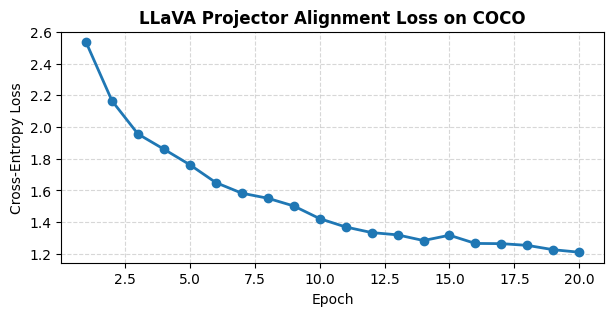

In [10]:
# Training configuration
optimizer = torch.optim.AdamW(projector.parameters(), lr=2e-3, weight_decay=1e-2)
EPOCHS = 20

print(f"=== Training Multimodal Projector on {len(train_coco)} Real COCO Samples ===")
vlm_model.train()
loss_history = []

for epoch in range(1, EPOCHS + 1):
    running_loss = 0.0
    for batch in train_loader:
        b_pixels = batch["pixel_values"].to(device)
        b_ids = batch["input_ids"].to(device)

        optimizer.zero_grad()
        loss, _ = vlm_model(pixel_values=b_pixels, text_input_ids=b_ids, labels=b_ids)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * b_pixels.size(0)

    epoch_loss = running_loss / len(train_coco)
    loss_history.append(epoch_loss)
    print(f"Epoch {epoch:2d}/{EPOCHS} | Multimodal Next-Token Loss: {epoch_loss:.4f}")

# Plot convergence
plt.figure(figsize=(7, 3))
plt.plot(range(1, EPOCHS + 1), loss_history, marker='o', color='#1f77b4', linewidth=2)
plt.title("LLaVA Projector Alignment Loss on COCO", fontweight='bold')
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [11]:
interact(
    run_interactive_vlm,
    sample_idx=IntSlider(value=10, min=0, max=len(coco_samples) - 1, step=1, description="Sample ID:"),
    prompt_prefix=Text(value="A photo of:", description="Prompt:"),
    max_new_tokens=IntSlider(value=12, min=5, max=30, step=1, description="Max Tokens:")
);

interactive(children=(IntSlider(value=10, description='Sample ID:', max=199), Text(value='A photo of:', descri…